In [1]:
import pandas as pd
import geopandas as gpd

In [2]:
oak_parcels = gpd.read_parquet("../data/processed/oak_parcels.parquet")

In [3]:
#ensure projected to crs in feet
#set to 2227: NAD83 / California zone 3 (US survey foot)
oak_parcels = oak_parcels.to_crs(epsg=2227)

#create a column with the square feet of each parcel
oak_parcels["sqft"] = oak_parcels.area

In [4]:
#aggregate based on parcel count and land area
sb79_scale_summary_df = oak_parcels.groupby('sb79_scale', dropna=False).agg(
    parcel_count=('sb79_scale', 'size'),
    total_sqft=('sqft', 'sum')
).reset_index()

#percentages relative to the citywide total
total_parcels = len(oak_parcels)
total_land = oak_parcels['sqft'].sum()

sb79_scale_summary_df['parcel_pct'] = (sb79_scale_summary_df['parcel_count'] / total_parcels * 100).round(2)
sb79_scale_summary_df['land_pct'] = (sb79_scale_summary_df['total_sqft'] / total_land * 100).round(2)

#clean display
sb79_scale_summary_df = sb79_scale_summary_df.sort_values(by='sb79_scale', na_position='last')
sb79_scale_summary_df

,sb79_scale,parcel_count,total_sqft,parcel_pct,land_pct
0,3.0,9226,5.622361e+07,25.71,12.06
1,4.0,19726,2.087853e+08,54.98,44.78
2,5.0,6174,1.356608e+08,17.21,29.10
3,6.0,106,1.327902e+06,0.30,0.28
4,NaN,646,6.426181e+07,1.80,13.78


Matplotlib is building the font cache; this may take a moment.


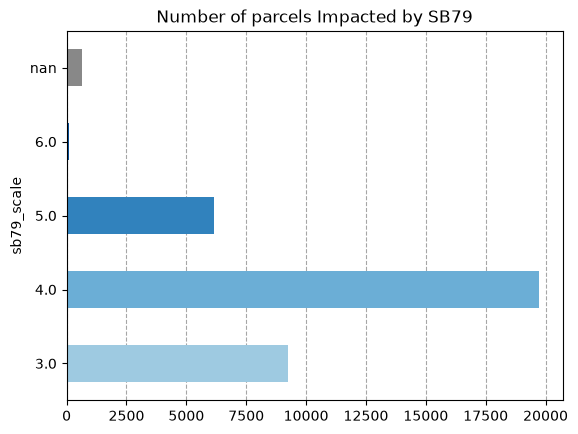

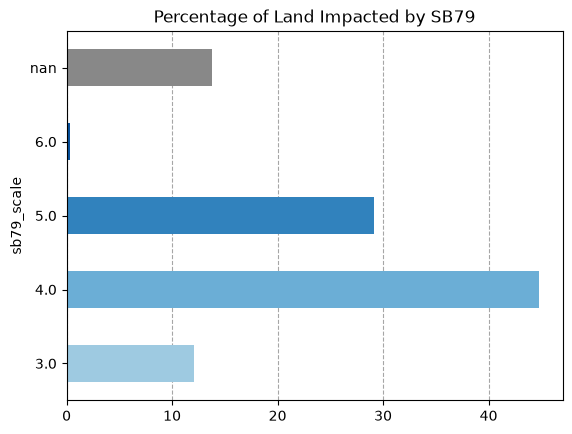

In [5]:
colors = {
    1: "#eff3ff",  #light blue
    2: "#c6dbef",
    3: "#9ecae1",
    4: "#6baed6",
    5: "#3182bd",
    6: "#08519c"   #dark blue
}

bar_colors = sb79_scale_summary_df['sb79_scale'].map(colors).fillna('#888888')

#plot parcel counts
sb79_parcel_chart = sb79_scale_summary_df.plot.barh(
    x='sb79_scale',
    y='parcel_count',
    color=bar_colors,
    legend=False,
    title='Number of parcels Impacted by SB79'
)

#plot the percentage of land
sb79_land_chart = sb79_scale_summary_df.plot.barh(
    x='sb79_scale',
    y='land_pct',
    color=bar_colors,
    legend=False,
    title='Percentage of Land Impacted by SB79'
)

sb79_parcel_chart.set_axisbelow(True)
sb79_parcel_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')
sb79_land_chart.set_axisbelow(True)
sb79_land_chart.grid(axis='x', linestyle='--', alpha=0.7, color='gray')

In [ ]:
#sb79_parcel_chart.get_figure(
#).savefig("../visualizations/sb79_parcel_count_chart.jpg", dpi=300, bbox_inches="tight")
#sb79_land_chart.get_figure(
#).savefig("../visualizations/sb79_land_pct_chart.jpg", dpi=300, bbox_inches="tight")

In [6]:
#set to geographic coordinate system WGS 84 (ESPG 4326) which uses latitude and longitude
oak_parcels_4326 = oak_parcels.to_crs(epsg=4326)

#map the parcels in Oakland assigned to each scale
sb79_scale_map = oak_parcels_4326.explore(
    column='sb79_scale',
    categorical=True,
    cmap='Blues',
    legend_kwds={'caption': 'SB79 Scale (1-6)'}
)

In [32]:
#sb79_scale_map.save("visualization/sb79_scale_map.html")